Trovati 7 file statepoint da analizzare.


/home/laptop_boz/miniconda3/envs/openmc-env/lib/python3.12/site-packages/openmc/statepoint.py:289: FutureWarning: The 'k_combined' property has been renamed to 'keff' and will be removed in a future version of OpenMC.
  warnings.warn(
/home/laptop_boz/miniconda3/envs/openmc-env/lib/python3.12/site-packages/openmc/statepoint.py:289: FutureWarning: The 'k_combined' property has been renamed to 'keff' and will be removed in a future version of OpenMC.
  warnings.warn(
/home/laptop_boz/miniconda3/envs/openmc-env/lib/python3.12/site-packages/openmc/statepoint.py:289: FutureWarning: The 'k_combined' property has been renamed to 'keff' and will be removed in a future version of OpenMC.
  warnings.warn(
/home/laptop_boz/miniconda3/envs/openmc-env/lib/python3.12/site-packages/openmc/statepoint.py:289: FutureWarning: The 'k_combined' property has been renamed to 'keff' and will be removed in a future version of OpenMC.
  warnings.warn(
/home/laptop_boz/miniconda3/envs/openmc-env/lib/python3.12/s


 TABELLA RIASSUNTIVA E REACTION RATES VS TEMPERATURA 
 T_fuel    k_eff    k_std  alpha_Doppler_pcm_K  fiss_thermal  cap_epithermal
    300 0.980581 0.000308                  NaN      0.338892        0.114850
    350 0.979823 0.000297            -1.577787      0.338502        0.115704
    400 0.979037 0.000325            -1.638922      0.338380        0.116410
    450 0.978475 0.000320            -1.172104      0.338143        0.117281
    500 0.977474 0.000305            -2.093455      0.337358        0.117756
    550 0.976502 0.000316            -2.037944      0.337167        0.118426
    600 0.976101 0.000335            -0.841682      0.337133        0.119388

Tabella salvata in 'risultati_doppler_tallies.csv'.
Grafico salvato con successo come 'analisi_doppler_tallies.png'.


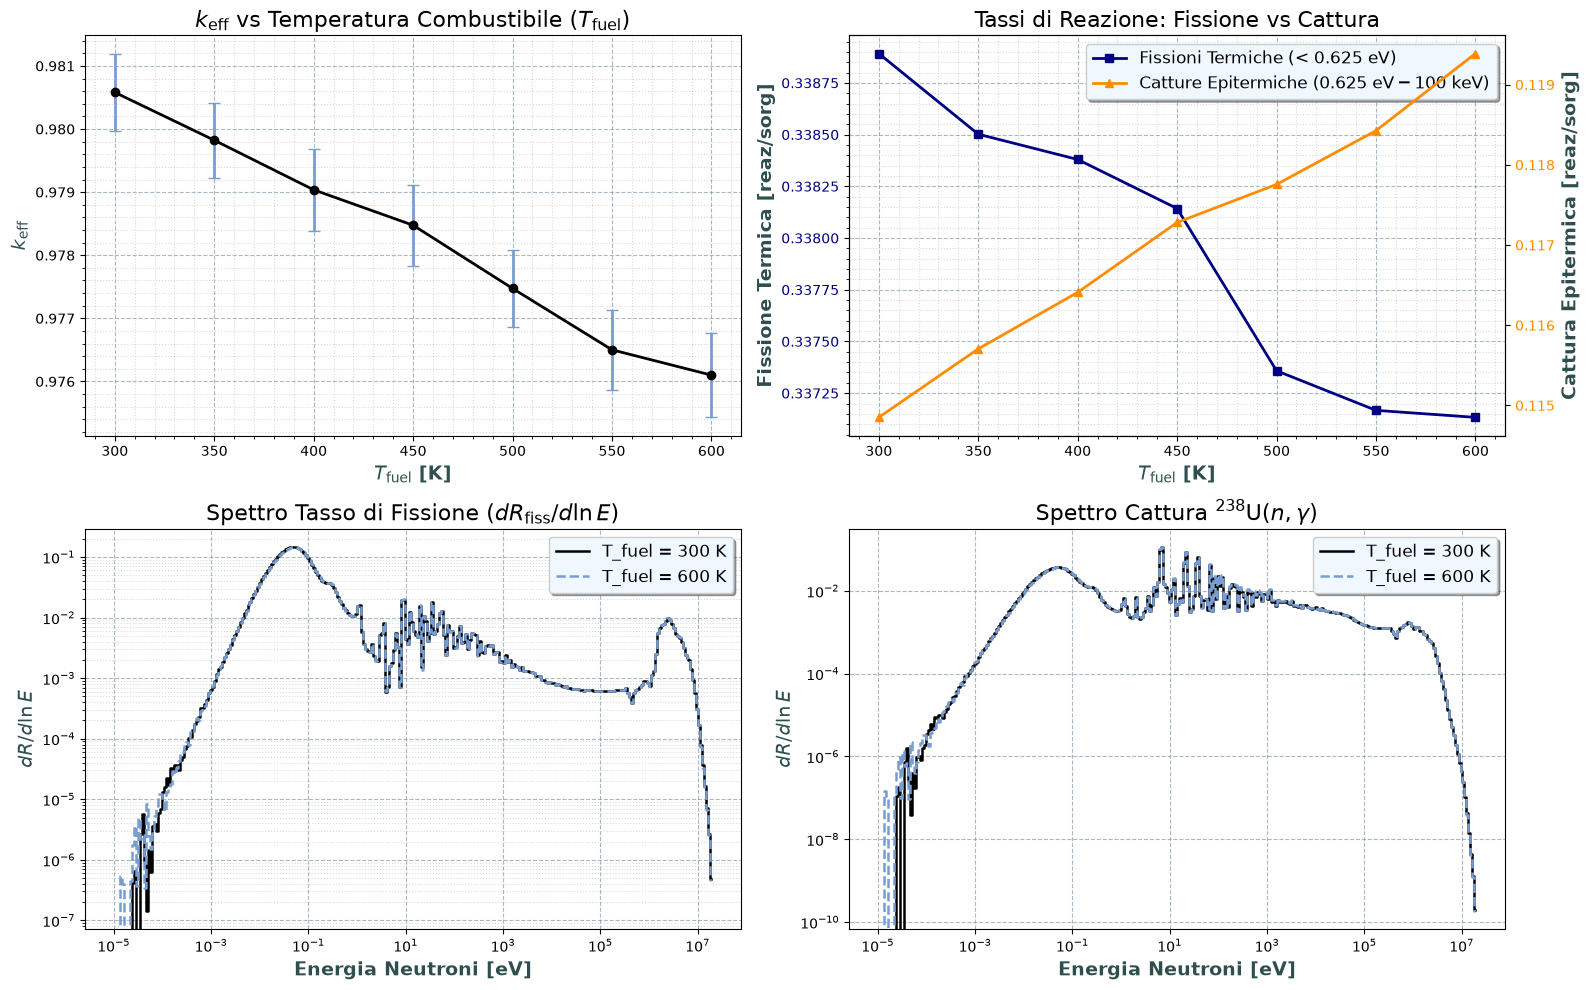

In [3]:
import glob
import os
import openmc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ==============================================================================
# 1. INDIVIDUAZIONE FILE STATEPOINT GENERATI
# ==============================================================================
# Trova tutti i file di statepoint salvati dal tuo ciclo
pattern = "statepoint_M*_P*_W*_T*.h5"
sp_files = sorted(glob.glob(pattern))

if not sp_files:
    raise FileNotFoundError(f"Nessun file trovato corrispondente al pattern '{pattern}'. Verifica la directory corrente.")

print(f"Trovati {len(sp_files)} file statepoint da analizzare.")

# Liste per memorizzare i risultati sintetici e gli spettri
data_summary = []
spectra_fission = {}
spectra_capture = {}
energies_mid = None

# ==============================================================================
# 2. ESTRAZIONE DATI DAI FILE STATEPOINT
# ==============================================================================
for sp_path in sp_files:
    # Estraiamo T_fuel dal nome del file (es. ..._T600.h5 -> 600)
    try:
        t_fuel_val = int(sp_path.split("_T")[-1].replace(".h5", ""))
    except ValueError:
        continue

    with openmc.StatePoint(sp_path) as sp:
        k_comb = sp.k_combined
        
        # Recupero Tallies tramite il nome definito nello script
        tally_groups = sp.get_tally(name='fuel_rr_groups')
        tally_spec = sp.get_tally(name='fuel_rr_spectrum')
        
        # Conversione in DataFrame pandas
        df_groups = tally_groups.get_pandas_dataframe()
        df_spec = tally_spec.get_pandas_dataframe()
        
        # --- A. REACTION RATES INTEGRATI NEI GRUPPI ENERGETICI ---
        # Gruppo Termico: energy high [eV] == 0.625
        # Gruppo Epitermico: energy low [eV] == 0.625 e energy high [eV] == 100000.0
        
        fiss_therm = df_groups[(df_groups['score'] == 'fission') & (df_groups['energy high [eV]'] <= 0.625)]['mean'].values[0]
        fiss_tot = df_groups[(df_groups['score'] == 'fission')]['mean'].sum()
        
        cap_epith = df_groups[(df_groups['score'] == '(n,gamma)') & (df_groups['energy low [eV]'] >= 0.625) & (df_groups['energy high [eV]'] <= 100.0e3)]['mean'].values[0]
        cap_therm = df_groups[(df_groups['score'] == '(n,gamma)') & (df_groups['energy high [eV]'] <= 0.625)]['mean'].values[0]
        flux_therm = df_groups[(df_groups['score'] == 'flux') & (df_groups['energy high [eV]'] <= 0.625)]['mean'].values[0]
        
        data_summary.append({
            'T_fuel': t_fuel_val,
            'k_eff': k_comb.nominal_value,
            'k_std': k_comb.std_dev,
            'fiss_thermal': fiss_therm,
            'fiss_total': fiss_tot,
            'cap_epithermal': cap_epith,
            'cap_thermal': cap_therm,
            'flux_thermal': flux_therm
        })
        
        # --- B. SPETTRO ENERGETICO CONTINUO (300 BIN) ---
        df_fiss_spec = df_spec[df_spec['score'] == 'fission']
        df_cap_spec = df_spec[df_spec['score'] == '(n,gamma)']
        
        e_low = df_fiss_spec['energy low [eV]'].values
        e_high = df_fiss_spec['energy high [eV]'].values
        
        if energies_mid is None:
            # Media geometrica dei bin per la scala logaritmica
            energies_mid = np.sqrt(e_low * e_high)
            # Normalizzazione del reaction rate per unità di letargia: dR / d(ln E)
            delta_ln_e = np.log(e_high / e_low)
            
        spectra_fission[t_fuel_val] = df_fiss_spec['mean'].values / delta_ln_e
        spectra_capture[t_fuel_val] = df_cap_spec['mean'].values / delta_ln_e

# ==============================================================================
# 3. ELABORAZIONE TABELLARE E CALCOLO COEFFICIENTE DOPPLER
# ==============================================================================
df_res = pd.DataFrame(data_summary).sort_values(by='T_fuel').reset_index(drop=True)

# Calcolo del coefficiente Doppler puntuale alpha_D [pcm/K]
df_res['alpha_Doppler_pcm_K'] = np.nan
for i in range(1, len(df_res)):
    dk = df_res.loc[i, 'k_eff'] - df_res.loc[i-1, 'k_eff']
    dT = df_res.loc[i, 'T_fuel'] - df_res.loc[i-1, 'T_fuel']
    k_prod = df_res.loc[i, 'k_eff'] * df_res.loc[i-1, 'k_eff']
    df_res.loc[i, 'alpha_Doppler_pcm_K'] = (dk / k_prod / dT) * 1e5

print("\n" + "="*80)
print(" TABELLA RIASSUNTIVA E REACTION RATES VS TEMPERATURA ")
print("="*80)
print(df_res[['T_fuel', 'k_eff', 'k_std', 'alpha_Doppler_pcm_K', 'fiss_thermal', 'cap_epithermal']].to_string(index=False))

df_res.to_csv("risultati_doppler_tallies.csv", index=False)
print("\nTabella salvata in 'risultati_doppler_tallies.csv'.")

# ==============================================================================
# 4. GENERAZIONE GRAFICI
# ==============================================================================
# Dizionari per lo stile personalizzato dei font e della legenda
label_font = {'fontsize': 14, 'fontweight': 'bold', 'color': '#2F4F4F'}
title_font = {'fontsize': 16}
legend_kwargs = {'loc': 'upper right', 'frameon': True, 'shadow': True, 'fontsize': 12, 'facecolor': '#F0F8FF'}

def set_custom_grid(ax):
    ax.minorticks_on()
    ax.grid(which='major', linestyle='--', alpha=0.6, color='#778899')
    ax.grid(which='minor', linestyle=':', alpha=0.3, color='#778899')

fig, axs = plt.subplots(2, 2, figsize=(16, 10))

# --- Grafico 1: k_eff vs T_fuel ---
axs[0, 0].errorbar(df_res['T_fuel'], df_res['k_eff'], yerr=df_res['k_std']*2, 
                   fmt='-o', color='#000000', ecolor='#789DD1', capsize=4, linewidth=2)
axs[0, 0].set_title(r'$k_{\text{eff}}$ vs Temperatura Combustibile ($T_{\text{fuel}}$)', **title_font)
axs[0, 0].set_xlabel(r'$T_{\text{fuel}}$ [K]', **label_font)
axs[0, 0].set_ylabel(r'$k_{\text{eff}}$', **label_font)
set_custom_grid(axs[0, 0])

# --- Grafico 2: Trend Fissione Termica vs Cattura Epitermica ---
ax2 = axs[0, 1]
color1, color2 = 'navy', 'darkorange'

line1 = ax2.plot(df_res['T_fuel'], df_res['fiss_thermal'], '-s', color=color1, label='Fissioni Termiche (< 0.625 eV)', linewidth=2)
ax2.set_xlabel(r'$T_{\text{fuel}}$ [K]', **label_font)
ax2.set_ylabel('Fissione Termica [reaz/sorg]',  **label_font)
ax2.tick_params(axis='y', labelcolor=color1)
set_custom_grid(ax2)

ax2_twin = ax2.twinx()
line2 = ax2_twin.plot(df_res['T_fuel'], df_res['cap_epithermal'], '-^', color=color2, label=r'Catture Epitermiche ($0.625 \text{ eV} - 100 \text{ keV}$)', linewidth=2)
ax2_twin.set_ylabel('Cattura Epitermica [reaz/sorg]', **label_font)
ax2_twin.tick_params(axis='y', labelcolor=color2)

# Legend unificata
lines = line1 + line2
labels = [l.get_label() for l in lines]
ax2.legend(lines, labels, **legend_kwargs)
ax2.set_title('Tassi di Reazione: Fissione vs Cattura', **title_font)

# --- Grafico 3: Spettro Fissione Continua (300K vs Max Temp) ---
T_min, T_max = df_res['T_fuel'].min(), df_res['T_fuel'].max()
axs[1, 0].step(energies_mid, spectra_fission[T_min], where='mid', label=f'T_fuel = {T_min} K', color='#000000', linewidth=1.8)
axs[1, 0].step(energies_mid, spectra_fission[T_max], where='mid', label=f'T_fuel = {T_max} K', color='#789DD1', linestyle='--', linewidth=1.8)
axs[1, 0].set_xscale('log')
axs[1, 0].set_yscale('log')
axs[1, 0].set_title(r'Spettro Tasso di Fissione ($dR_{\text{fiss}} / d\ln E$)', **title_font)
axs[1, 0].set_xlabel('Energia Neutroni [eV]', **label_font)
axs[1, 0].set_ylabel(r'$dR / d\ln E$', **label_font)
axs[1, 0].legend(**legend_kwargs)
set_custom_grid(axs[1, 0])

# --- Grafico 4: Spettro Cattura Radiativa (300K vs Max Temp) ---
axs[1, 1].step(energies_mid, spectra_capture[T_min], where='mid', label=f'T_fuel = {T_min} K', color='#000000', linewidth=1.8)
axs[1, 1].step(energies_mid, spectra_capture[T_max], where='mid', label=f'T_fuel = {T_max} K', color='#789DD1', linestyle='--', linewidth=1.8)
axs[1, 1].set_xscale('log')
axs[1, 1].set_yscale('log')
axs[1, 1].set_title(r'Spettro Cattura $^{238}\text{U}(n,\gamma)$', **title_font)
axs[1, 1].set_xlabel('Energia Neutroni [eV]', **label_font)
axs[1, 1].set_ylabel(r'$dR / d\ln E$', **label_font)
axs[1, 1].legend(**legend_kwargs)
set_custom_grid(axs[1, 1])

plt.tight_layout()
plt.savefig("analisi_doppler_tallies.png", dpi=300)
print("Grafico salvato con successo come 'analisi_doppler_tallies.png'.")
plt.show()

Trovati 7 file statepoint da analizzare.

 RISPOSTA ALLA DOMANDA DEL PROFESSORE 
 T_fuel  fiss_total  fiss_total_std  fiss_thermal  fiss_thermal_std
    300    0.399106        0.000189      0.338892          0.000188
    350    0.398733        0.000177      0.338502          0.000175
    400    0.398622        0.000167      0.338380          0.000165
    450    0.398330        0.000187      0.338143          0.000185
    500    0.397562        0.000194      0.337358          0.000192
    550    0.397347        0.000203      0.337167          0.000201
    600    0.397351        0.000190      0.337133          0.000189
--------------------------------------------------------------------------------
DOMANDA: 'Se ho + neutroni termici (per via del pitch maggiorato) E se aumento la temperatura, le fissioni aumentano?'
RISPOSTA: NO. Passando da 300 K a 600 K, le fissioni TOTALI sono DIMINUITE del 0.440%.

Grafico salvato con successo come 'fission_rate_vs_T_errors.png'.


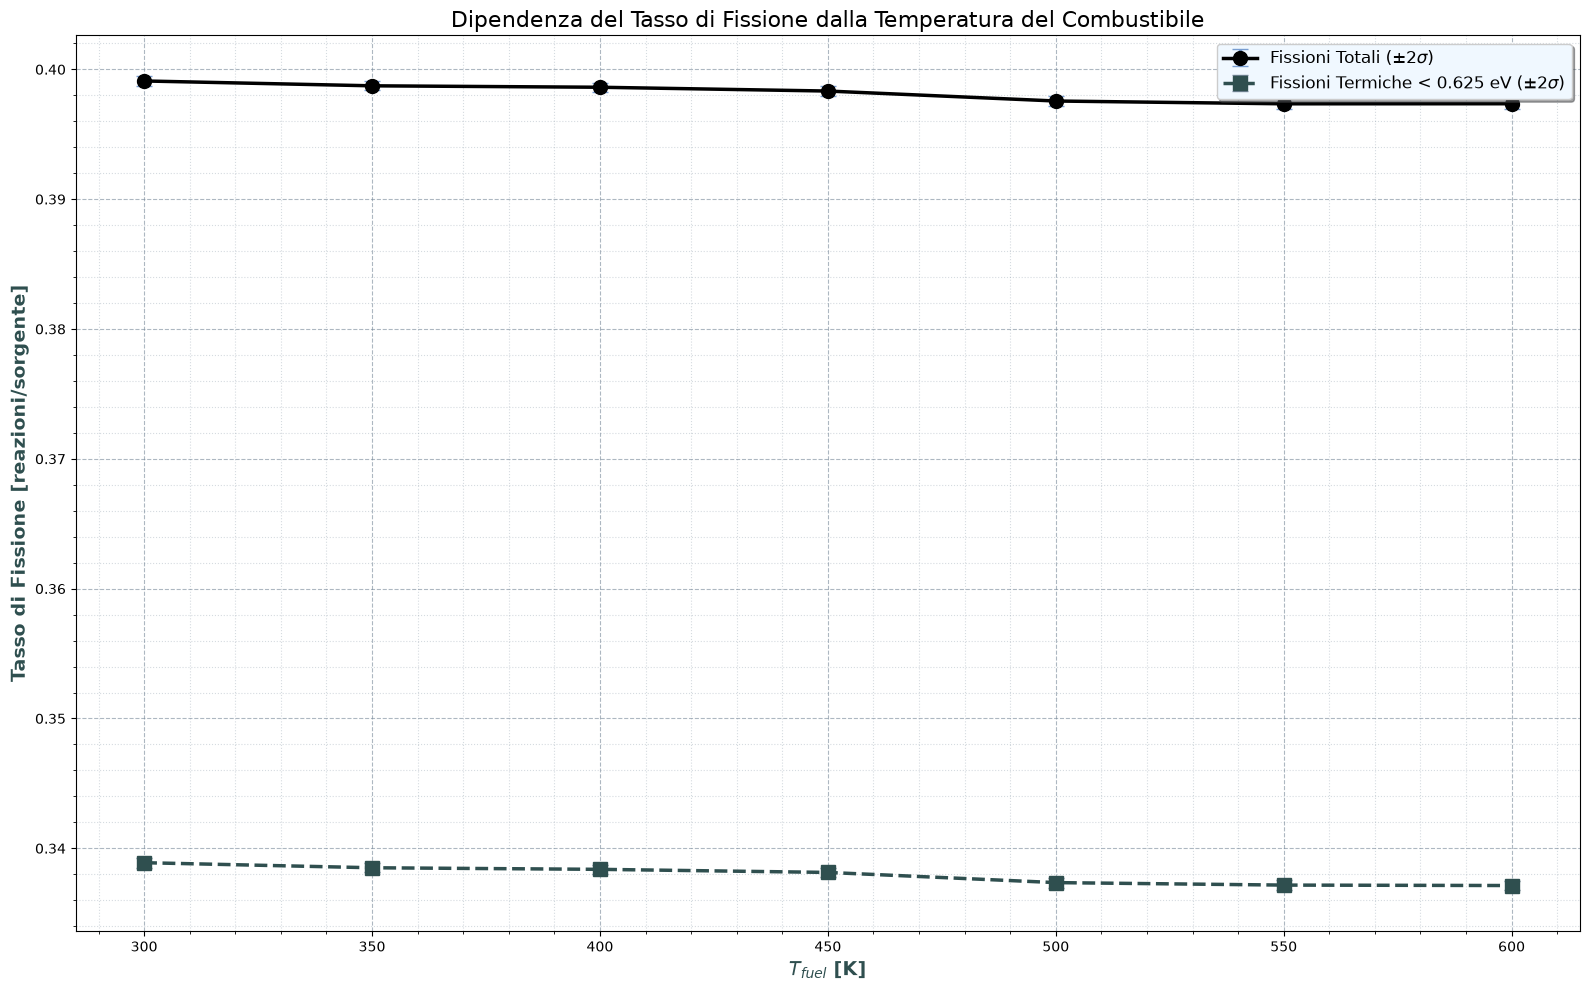

In [4]:
import glob
import os
import openmc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ==============================================================================
# 1. INDIVIDUAZIONE FILE STATEPOINT GENERATI
# ==============================================================================
pattern = "statepoint_M*_P*_W*_T*.h5"
sp_files = sorted(glob.glob(pattern))

if not sp_files:
    raise FileNotFoundError(f"Nessun file trovato corrispondente al pattern '{pattern}'. Verifica la directory corrente.")

print(f"Trovati {len(sp_files)} file statepoint da analizzare.")

data_summary = []

# ==============================================================================
# 2. ESTRAZIONE DATI (MEDIE ED ERRORI) DAI FILE STATEPOINT
# ==============================================================================
for sp_path in sp_files:
    try:
        t_fuel_val = int(sp_path.split("_T")[-1].replace(".h5", ""))
    except ValueError:
        continue

    with openmc.StatePoint(sp_path) as sp:
        tally_groups = sp.get_tally(name='fuel_rr_groups')
        df_groups = tally_groups.get_pandas_dataframe()
        
        # --- Fissioni Totali ---
        # Media: somma di tutti i gruppi
        fiss_tot = df_groups[(df_groups['score'] == 'fission')]['mean'].sum()
        # Errore (1 sigma): radice della somma delle varianze
        fiss_tot_std = np.sqrt((df_groups[(df_groups['score'] == 'fission')]['std. dev.']**2).sum())
        
        # --- Fissioni Termiche (< 0.625 eV) ---
        mask_therm = (df_groups['score'] == 'fission') & (df_groups['energy high [eV]'] <= 0.625)
        fiss_therm = df_groups[mask_therm]['mean'].values[0]
        fiss_therm_std = df_groups[mask_therm]['std. dev.'].values[0]
        
        data_summary.append({
            'T_fuel': t_fuel_val,
            'fiss_total': fiss_tot,
            'fiss_total_std': fiss_tot_std,
            'fiss_thermal': fiss_therm,
            'fiss_thermal_std': fiss_therm_std
        })

# ==============================================================================
# 3. ELABORAZIONE TABELLARE E RISPOSTA AL PROFESSORE
# ==============================================================================
df_res = pd.DataFrame(data_summary).sort_values(by='T_fuel').reset_index(drop=True)

t_min = df_res['T_fuel'].min()
t_max = df_res['T_fuel'].max()
fiss_min_t = df_res.loc[df_res['T_fuel'] == t_min, 'fiss_total'].values[0]
fiss_max_t = df_res.loc[df_res['T_fuel'] == t_max, 'fiss_total'].values[0]

delta_fiss = fiss_max_t - fiss_min_t
perc_fiss = (delta_fiss / fiss_min_t) * 100

print("\n" + "="*80)
print(" RISPOSTA ALLA DOMANDA DEL PROFESSORE ")
print("="*80)
print(df_res[['T_fuel', 'fiss_total', 'fiss_total_std', 'fiss_thermal', 'fiss_thermal_std']].to_string(index=False))
print("-" * 80)
print("DOMANDA: 'Se ho + neutroni termici (per via del pitch maggiorato) E se aumento la temperatura, le fissioni aumentano?'")
if delta_fiss > 0:
    print(f"RISPOSTA: SÌ. Passando da {t_min} K a {t_max} K, le fissioni TOTALI sono AUMENTATE del {perc_fiss:.3f}%.")
    print("CONCLUSIONE: Questo dimostra la motivazione del Doppler positivo a questo pitch.")
else:
    print(f"RISPOSTA: NO. Passando da {t_min} K a {t_max} K, le fissioni TOTALI sono DIMINUITE del {abs(perc_fiss):.3f}%.")
print("="*80)

# ==============================================================================
# 4. GENERAZIONE GRAFICO CON BARRE DI ERRORE
# ==============================================================================
# Stile personalizzato per font e legenda
label_font = {'fontsize': 14, 'fontweight': 'bold', 'color': '#2F4F4F'}
title_font = {'fontsize': 16}
legend_kwargs = {'loc': 'upper right', 'frameon': True, 'shadow': True, 'fontsize': 12, 'facecolor': '#F0F8FF'}

def set_custom_grid(ax):
    ax.minorticks_on()
    ax.grid(which='major', linestyle='--', alpha=0.6, color='#778899')
    ax.grid(which='minor', linestyle=':', alpha=0.3, color='#778899')

fig, ax = plt.subplots(figsize=(16, 10))

# Plot Fissioni Totali con barre di errore a 2 sigma (95% di confidenza)
ax.errorbar(df_res['T_fuel'], df_res['fiss_total'], yerr=df_res['fiss_total_std']*2, 
            fmt='-o', color='#000000', ecolor='#789DD1', capsize=6, linewidth=2.5, markersize=10, 
            label=r'Fissioni Totali ($\pm 2\sigma$)')

# Plot Fissioni Termiche con barre di errore a 2 sigma
ax.errorbar(df_res['T_fuel'], df_res['fiss_thermal'], yerr=df_res['fiss_thermal_std']*2, 
            fmt='--s', color='#2F4F4F', ecolor='#778899', capsize=6, linewidth=2.5, markersize=10, 
            label=r'Fissioni Termiche < 0.625 eV ($\pm 2\sigma$)')

ax.set_title('Dipendenza del Tasso di Fissione dalla Temperatura del Combustibile', **title_font)
ax.set_xlabel(r'$T_{fuel}$ [K]', **label_font)
ax.set_ylabel('Tasso di Fissione [reazioni/sorgente]', **label_font)
set_custom_grid(ax)
ax.legend(**legend_kwargs)

plt.tight_layout()
plt.savefig("fission_rate_vs_T_errors.png", dpi=300)
print("\nGrafico salvato con successo come 'fission_rate_vs_T_errors.png'.")
plt.show()